# Capítulo 5 · Actividad: Titanic, ¿árbol o vecinos?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/riosinda/ml-course/blob/main/notebooks/exercises/chapter_05/04_actividad_titanic_arbol_knn.ipynb)

Compara un **árbol de decisión** y **KNN** para predecir si un pasajero del Titanic sobrevivió. Primero entiende los datos; el preprocesamiento lo decides tú. Los dos modelos tienen que evaluarse sobre la misma división de train y test, y con las mismas particiones de validación cruzada.

Cada fila es un pasajero. Para esta actividad usa las siguientes variables:

| Variable | Significado |
|---|---|
| `survived` | **Target**: `0` = no sobrevivió, `1` = sobrevivió |
| `pclass` | Clase del boleto: primera, segunda o tercera |
| `sex` | Sexo del pasajero |
| `age` | Edad en años |
| `sibsp` | Número de hermanos y cónyuges a bordo |
| `parch` | Número de padres e hijos a bordo |
| `fare` | Tarifa pagada |
| `embarked` | Puerto de embarque: `C`, `Q` o `S` |

Hay valores faltantes en `age` y `embarked`. Las clases de supervivencia no están balanceadas y las variables numéricas tienen escalas distintas.

**Usa únicamente las siete variables predictoras de la tabla.** El CSV contiene otras columnas: `alive`, por ejemplo, expresa la misma respuesta que `survived`. Incluirla entre las entradas sería una fuga de información: el modelo recibiría la respuesta que debe predecir. Tampoco incluyas `survived` entre las entradas.

Como mínimo, tu notebook debe incluir:

- La exploración de antes de modelar: forma de la tabla, nulos, balance de supervivencia, distribuciones y relación de las variables con la supervivencia.
- Una división estratificada de train y test y validación cruzada estratificada sobre train. Usa `random_state=42` en la división, en el árbol y al mezclar las particiones de validación.
- Un **árbol de decisión** y un **KNN**, los dos para clasificar. Decide cómo tratar los nulos, cómo codificar las variables categóricas y si estandarizas las numéricas: a KNN la escala le importa, al árbol no. Integra el preprocesamiento en un `Pipeline` para que se ajuste solo con los datos de entrenamiento de cada partición.
- La profundidad del árbol (y `min_samples_leaf`, si quieres) elegida con `GridSearchCV` sobre la validación cruzada.
- Para KNN, varios valores de `k`, incluyendo `k=1`, una **gráfica de la accuracy de train y de validación contra `k`** y el `k` que alcanza el máximo en validación. Distingue la accuracy sobre los mismos datos usados para entrenar de la obtenida en las particiones de validación. El test se usa una vez, al final, para evaluar ambos modelos elegidos, no para escoger hiperparámetros.
- Una **tabla** con los dos modelos: accuracy en validación cruzada (media y desviación estándar) y en prueba, y la matriz de confusión de cada uno en prueba. Compara también con una referencia sencilla: predecir siempre la clase mayoritaria de train.
- Tus **conclusiones**: con cuál te quedas y por qué. Explica la diferencia entre train y validación con `k=1`, cómo cambia al aumentar `k` y qué errores comete cada modelo al predecir supervivencia.

No hay una accuracy objetivo ni un ganador obligatorio. El objetivo es justificar la comparación con los resultados: `k=1` puede generalizar bien y la curva de validación no tiene por qué mejorar siempre al aumentar `k`. Si los modelos obtienen resultados muy parecidos, reconócelo en tus conclusiones.

1. **Copia esta notebook a `workspace/`** y trabaja sobre la copia.
2. Si todavía no tienes los datos: `uv run python scripts/download_data.py`


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
raiz = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
df = pd.read_csv(raiz / "data" / "titanic.csv")
df.head()


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [6]:
target = 'survived'
features = ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']
df_modelo = df[[target] + features].copy()

In [7]:
print("Dimensiones (filas, columnas):", df_modelo.shape)
display(df_modelo.head())
df_modelo.info()

Dimensiones (filas, columnas): (891, 8)


,survived,pclass,sex,age,sibsp,parch,fare,embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   survived  891 non-null    int64  
 1   pclass    891 non-null    int64  
 2   sex       891 non-null    object 
 3   age       714 non-null    float64
 4   sibsp     891 non-null    int64  
 5   parch     891 non-null    int64  
 6   fare      891 non-null    float64
 7   embarked  889 non-null    object 
dtypes: float64(2), int64(4), object(2)
memory usage: 55.8+ KB


In [8]:
print("\nValores nulos por columna:")
print(df_modelo.isnull().sum())


Valores nulos por columna:
survived      0
pclass        0
sex           0
age         177
sibsp         0
parch         0
fare          0
embarked      2
dtype: int64


In [9]:
print("\nBalance de clases (proporción de supervivencia):")
print(df_modelo[target].value_counts(normalize=True).round(3))


Balance de clases (proporción de supervivencia):
survived
0    0.616
1    0.384
Name: proportion, dtype: float64


In [14]:
print("--- Valores nulos ---")
print(df.isna().sum())

duplicados = df.duplicated().sum()
print(f"\nFilas duplicadas: {duplicados}")

if duplicados > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print(f"Filas tras eliminar duplicados: {len(df)}")

--- Valores nulos ---
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

Filas duplicadas: 107
Filas tras eliminar duplicados: 784


d:\Aplicaciones\Anaonda\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


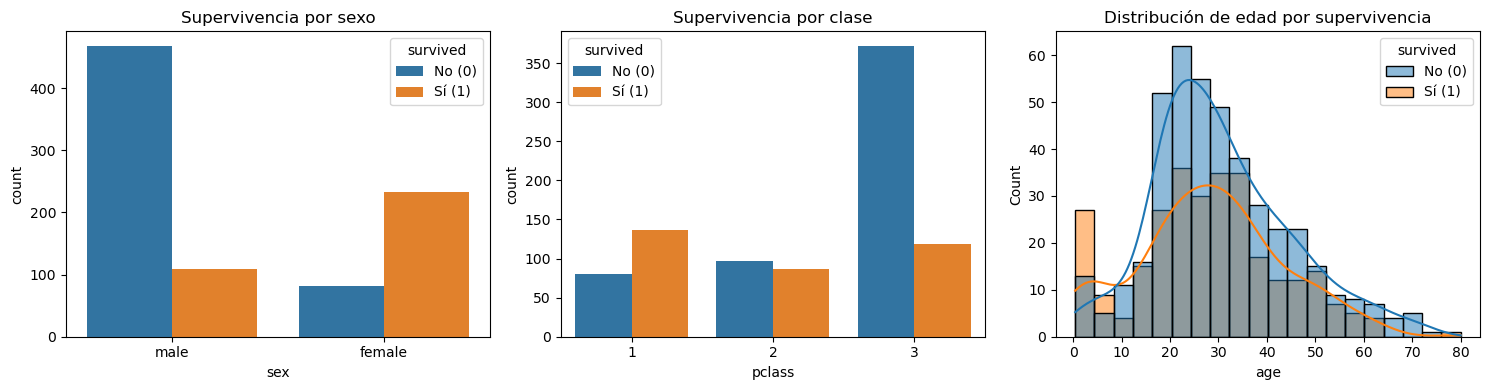

In [16]:
df_plot = df_modelo.copy()
df_plot['survived'] = df_plot['survived'].map({0: 'No (0)', 1: 'Sí (1)'})

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.countplot(data=df_plot, x='sex', hue='survived', ax=axes[0])
axes[0].set_title('Supervivencia por sexo')

sns.countplot(data=df_plot, x='pclass', hue='survived', ax=axes[1])
axes[1].set_title('Supervivencia por clase')

sns.histplot(data=df_plot, x='age', hue='survived', kde=True, ax=axes[2])
axes[2].set_title('Distribución de edad por supervivencia')

plt.tight_layout()
plt.show()



In [17]:
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

In [ ]:
X = df_modelo[features]
y = df_modelo[target]

# División en train (80%) y test (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)